<a href="https://colab.research.google.com/github/javanmardi298/products_search/blob/main/01_retrieval_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q rank-bm25 sentence-transformers

In [2]:
import os

user = "javanmardi298"
repo = "products_search"

os.chdir("/content")
if not os.path.exists(repo):
    os.system(f"git clone https://github.com/{user}/{repo}.git")
else:
    os.system(f"cd {repo} && git pull")

if os.path.exists(repo + "/shop_common.py"):
    os.chdir(repo)
print(os.getcwd())
print(os.listdir())

/content/products_search
['README.md', '.gitignore', 'LICENSE', 'results', 'shop_common.py', 'check_common.py', '.git', 'requirements.txt']


In [3]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

from shop_common import load_data, make_texts, make_split, evaluate, bootstrap, short_name

print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
os.makedirs("cache", exist_ok=True)
os.makedirs("results", exist_ok=True)

EMB_MODEL = "BAAI/bge-small-en-v1.5"
RERANK_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"
K = 50

True Tesla T4


## Data

In [4]:
products, queries, labels, qrels, query_text = load_data()
print(len(products), "products")
print(len(queries), "queries")
print(len(labels), "labels")
print(labels["label"].value_counts())
queries.head()

downloading product.csv
downloading query.csv
downloading label.csv
42994 products
480 queries
233448 labels
label
Partial       146633
Irrelevant     61201
Exact          25614
Name: count, dtype: int64


,query_id,query,query_class
0,0,salon chair,Massage Chairs
1,1,smart coffee table,Coffee & Cocktail Tables
2,2,dinosaur,Kids Wall Décor
3,3,turquoise pillows,Accent Pillows
4,4,chair and a half recliner,Recliners


In [5]:
texts = make_texts(products)
ids = products["product_id"].values
rich_by_id = dict(zip(ids, texts["rich"]))

split = make_split(qrels)
dev = split["dev"]
test = split["test"]
print(len(dev), len(test))
print(texts["rich"][0])

160 320
solid wood platform bed
Category: Beds (Furniture / Bedroom Furniture / Beds & Headboards / Beds / Twin Beds)
Features: overallwidth-sidetoside: 64.7; dsprimaryproductstyle: modern; countryoforigin-additionaldetails: made in viet nam; headboardtype: slat; headboardheight-toptobedframe: 25.35; weightcapacity: 500; estimatedtimetosetup: 120; overalllength-headtotoe: 77.9; levelofassembly: full assembly needed; overallproductweight: 78.7; woodspecies: rubberwood; numberofslatsincluded: 12; overallheight-toptobottom: 39.6; headboardshape: rectangular; woodspecies: acacia
Description: good , deep sleep can be quite difficult to have in this busy age . fortunately , there ’ s an antidote to such a problem : a nice , quality bed frame like the acacia kaylin . solidly constructed from acacia wood , this bed frame will stand the test of time and is fit to rest your shoulders on for years and years . its sleek , natural wood grain appearance provides a pleasant aesthetic to adorn any bed

## Search

### 1. Dense search (embeddings)



In [6]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer(EMB_MODEL, device="cuda")
model.max_seq_length = 256
prefix = "Represent this sentence for searching relevant passages: "  # bge wants this before queries

emb = {}
for mode in ["basic", "rich"]:
    file = f"cache/emb_{mode}_{short_name(EMB_MODEL)}.npy"
    if os.path.exists(file):
        emb[mode] = np.load(file)
    else:
        emb[mode] = model.encode(texts[mode], batch_size=256, normalize_embeddings=True, show_progress_bar=True)
        np.save(file, emb[mode])
    print(mode, emb[mode].shape)


def top_k(scores, k):
    best = np.argsort(-scores)[:k]
    return ids[best].tolist()


def dense_search(query, mode, k=K):
    q = model.encode(prefix + query, normalize_embeddings=True)
    return top_k(emb[mode] @ q, k)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (7 outputs left out)

Batches:   0%|          | 0/168 [00:00<?, ?it/s]

basic (42994, 384)


Batches:   0%|          | 0/168 [00:00<?, ?it/s]

rich (42994, 384)


### 2. BM25

In [7]:
import re
from rank_bm25 import BM25Okapi

stopwords = ["a", "an", "the", "and", "or", "for", "of", "to", "in", "on", "with", "by", "is", "it", "this"]


def tokenize(text):
    words = re.findall(r"[a-z0-9]+", text.lower())
    return [w for w in words if w not in stopwords]


bm25 = {}
for mode in ["basic", "rich"]:
    bm25[mode] = BM25Okapi([tokenize(t) for t in texts[mode]])


def bm25_search(query, mode, k=K):
    return top_k(bm25[mode].get_scores(tokenize(query)), k)

### 3. Hybrid search (RRF)



In [8]:
def rrf(lists, k=60):
    scores = {}
    for lst in lists:
        for rank, pid in enumerate(lst):
            scores[pid] = scores.get(pid, 0) + 1 / (k + rank + 1)
    return sorted(scores, key=scores.get, reverse=True)


def hybrid_search(query, k=K):
    a = dense_search(query, "rich", 100)
    b = bm25_search(query, "rich", 100)
    return rrf([a, b])[:k]

### 4. Reranker

In [9]:
from sentence_transformers import CrossEncoder

reranker = CrossEncoder(RERANK_MODEL, max_length=256, device="cuda")


def rerank_search(query, k=K):
    cands = hybrid_search(query, 50)
    scores = reranker.predict([(query, rich_by_id[p]) for p in cands], batch_size=64)
    order = np.argsort(-scores)
    return [cands[i] for i in order][:k]

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

## Compare the search methods on dev

In [10]:
methods = {
    "dense / basic": lambda q: dense_search(q, "basic"),
    "bm25 / basic": lambda q: bm25_search(q, "basic"),
    "dense / rich": lambda q: dense_search(q, "rich"),
    "bm25 / rich": lambda q: bm25_search(q, "rich"),
    "hybrid": hybrid_search,
    "hybrid + rerank": rerank_search,
}

results = {}
scores_per_query = {}
for name, search in methods.items():
    run = {}
    times = []
    for q in tqdm(dev, desc=name):
        start = time.time()
        run[q] = search(query_text[q])
        times.append(time.time() - start)
    df = evaluate(run, qrels)
    scores_per_query[name] = df
    row = df.mean().round(3).to_dict()
    row["ms/query"] = round(np.median(times) * 1000, 1)
    results[name] = row

table = pd.DataFrame(results).T
table.to_csv("results/ablation_dev.csv")
table

dense / basic:   0%|          | 0/160 [00:00<?, ?it/s]

bm25 / basic:   0%|          | 0/160 [00:00<?, ?it/s]

dense / rich:   0%|          | 0/160 [00:00<?, ?it/s]

bm25 / rich:   0%|          | 0/160 [00:00<?, ?it/s]

hybrid:   0%|          | 0/160 [00:00<?, ?it/s]

hybrid + rerank:   0%|          | 0/160 [00:00<?, ?it/s]

,ndcg@10,recall@10,mrr,judged@10,ms/query
dense / basic,0.700,0.275,0.518,0.842,22.3
bm25 / basic,0.602,0.259,0.466,0.781,40.9
dense / rich,0.692,0.269,0.512,0.823,22.6
bm25 / rich,0.630,0.250,0.492,0.799,52.2
hybrid,0.706,0.268,0.543,0.853,108.0
hybrid + rerank,0.736,0.311,0.560,0.868,276.0


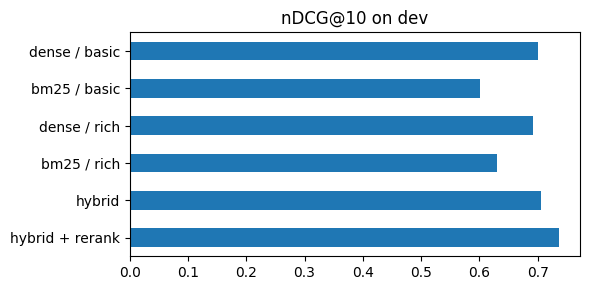

In [11]:
table["ndcg@10"].plot(kind="barh", figsize=(6, 3), title="nDCG@10 on dev")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("results/ablation_dev.png", dpi=150)
plt.show()

### Bootstrap over the 160 dev queries, each method against the baseline (dense / basic).

In [12]:
base = scores_per_query["dense / basic"]["ndcg@10"]
sig = {}
for name in methods:
    if name != "dense / basic":
        sig[name] = bootstrap(base, scores_per_query[name]["ndcg@10"])

sig = pd.DataFrame(sig).T
sig.to_csv("results/ablation_significance_dev.csv")
sig

,diff,low,high,p
bm25 / basic,-0.098,-0.133,-0.065,1.0000
dense / rich,-0.007,-0.027,0.012,0.7689
bm25 / rich,-0.070,-0.106,-0.035,1.0000
hybrid,0.007,-0.018,0.031,0.2991
hybrid + rerank,0.037,0.011,0.063,0.0020


## Save the rankings; v1 = dense search on basic text, v2 = hybrid + rerank. All 480 queries.

In [13]:
rankings = {"v1": {}, "v2": {}}
for q in tqdm(dev + test):
    rankings["v1"][q] = dense_search(query_text[q], "basic")
    rankings["v2"][q] = rerank_search(query_text[q])

with open("results/rankings.json", "w") as f:
    json.dump(rankings, f)

# should match the table above
print(evaluate({q: rankings["v1"][q] for q in dev}, qrels)["ndcg@10"].mean())
print(evaluate({q: rankings["v2"][q] for q in dev}, qrels)["ndcg@10"].mean())

  0%|          | 0/480 [00:00<?, ?it/s]

0.6996965323235124
0.7364111004370754


### versions


In [15]:
import platform
from importlib.metadata import version

info = {
    "python": platform.python_version(),
    "gpu": torch.cuda.get_device_name(0),
    "torch": version("torch"),
    "sentence-transformers": version("sentence-transformers"),
    "rank-bm25": version("rank-bm25"),
    "embedding model": EMB_MODEL,
    "reranker": RERANK_MODEL,
}
with open("results/env_retrieval.json", "w") as f:
    json.dump(info, f, indent=2)
info

{'python': '3.13.16',
 'gpu': 'Tesla T4',
 'torch': '2.11.0+cu130',
 'sentence-transformers': '5.7.0',
 'rank-bm25': '0.2.2',
 'embedding model': 'BAAI/bge-small-en-v1.5',
 'reranker': 'cross-encoder/ms-marco-MiniLM-L-6-v2'}

In [16]:
from google.colab import files

os.system("zip -r /content/colab_results.zip results split.json")
files.download("/content/colab_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>